In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/netflix_titles.csv')

df.head()


,duration_minutes,duration_seasons,type,title,date_added,release_year,rating,description,show_id
0,90,NaN,Movie,Norm of the North: King Sized Adventure,9/9/2019,2019.0,TV-PG,Before planning an awesome wedding for his gra...,81145628.0
1,94,NaN,Movie,Jandino: Whatever it Takes,9/9/2016,2016.0,TV-MA,Jandino Asporaat riffs on the challenges of ra...,80117401.0
2,NaN,1,TV Show,Transformers Prime,9/8/2018,2013.0,TV-Y7-FV,"With the help of three human allies, the Autob...",70234439.0
3,NaN,1,TV Show,Transformers: Robots in Disguise,9/8/2018,2016.0,TV-Y7,When a prison ship crash unleashes hundreds of...,80058654.0
4,99,NaN,Movie,#realityhigh,9/8/2017,2017.0,TV-14,When nerdy high schooler Dani finally attracts...,80125979.0


In [7]:

print("Dataset Shape:", df.shape)

df.info()


print("\nMissing Values:")
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())



Dataset Shape: (6236, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6236 entries, 0 to 6235
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   duration_minutes  4267 non-null   object 
 1   duration_seasons  1971 non-null   object 
 2   type              6235 non-null   object 
 3   title             6235 non-null   object 
 4   date_added        6223 non-null   object 
 5   release_year      6234 non-null   float64
 6   rating            6223 non-null   object 
 7   description       6233 non-null   object 
 8   show_id           6232 non-null   float64
dtypes: float64(2), object(7)
memory usage: 438.6+ KB

Missing Values:
duration_minutes    1969
duration_seasons    4265
type                   1
title                  1
date_added            13
release_year           2
rating                13
description            3
show_id                4
dtype: int64
Duplicate Rows: 0


In [8]:
print("Missing values before cleaning:")
print(df.isnull().sum())


Missing values before cleaning:
duration_minutes    1969
duration_seasons    4265
type                   1
title                  1
date_added            13
release_year           2
rating                13
description            3
show_id                4
dtype: int64


In [9]:

df['duration_minutes'] = df['duration_minutes'].fillna(0)
df['duration_seasons'] = df['duration_seasons'].fillna(0)
df['rating'] = df['rating'].fillna('Not Rated')
df['date_added'] = df['date_added'].fillna('Not Available')
df['release_year'] = df['release_year'].fillna(0)
df['description'] = df['description'].fillna('No Description')

df = df.drop_duplicates()

print(df.isnull().sum())

print("\nFinal Dataset Shape:", df.shape)


duration_minutes    0
duration_seasons    0
type                1
title               1
date_added          0
release_year        0
rating              0
description         0
show_id             4
dtype: int64

Final Dataset Shape: (6236, 9)


In [10]:


df = df.dropna(subset=['type', 'title', 'show_id'])

print(df.isnull().sum())

print("\nFinal Dataset:", df.shape)


duration_minutes    0
duration_seasons    0
type                0
title               0
date_added          0
release_year        0
rating              0
description         0
show_id             0
dtype: int64

Final Dataset: (6232, 9)


type
Movie      4263
TV Show    1969
Name: count, dtype: int64


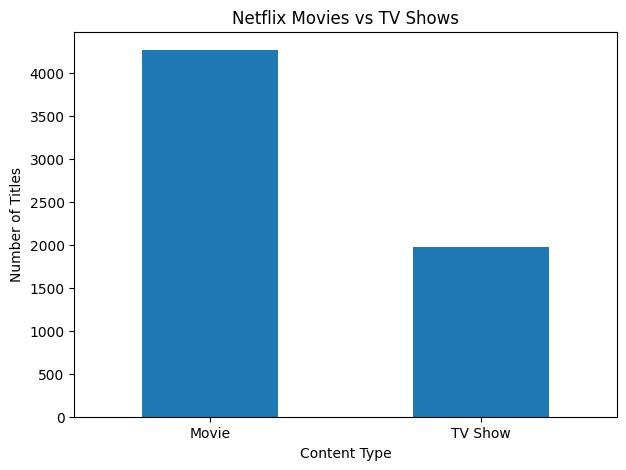

In [11]:

print(df['type'].value_counts())

df['type'].value_counts().plot(kind='bar', figsize=(7, 5))

plt.title('Netflix Movies vs TV Shows')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)
plt.show()


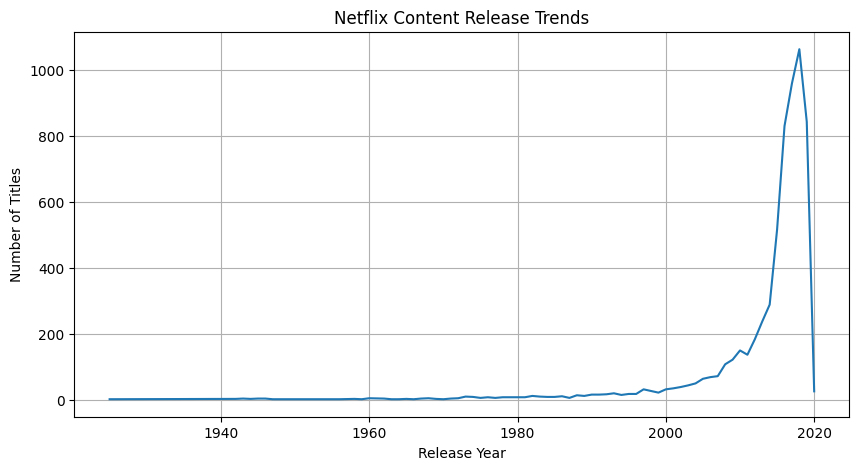

In [12]:

year_data = df[df['release_year'] > 0]

year_count = year_data['release_year'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(year_count.index, year_count.values)

plt.title('Netflix Content Release Trends')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.grid()
plt.show()



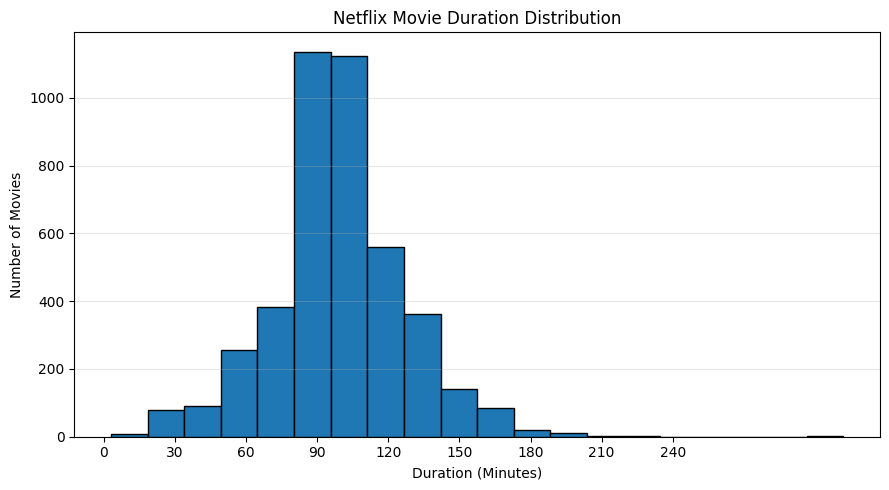

In [13]:

df['duration_minutes'] = pd.to_numeric(df['duration_minutes'], errors='coerce')


movies = df[(df['type'] == 'Movie') & (df['duration_minutes'] > 0)]

plt.figure(figsize=(9, 5))

plt.hist(movies['duration_minutes'], bins=20, edgecolor='black')

plt.title('Netflix Movie Duration Distribution')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Number of Movies')

plt.xticks(range(0, 251, 30))
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()




## Results and Observations

1. The dataset contains 6,232 Netflix titles after cleaning.
2. Movies (4,263) are more common than TV Shows (1,969).
3. Netflix content releases increased significantly after 2000.
4. Most movies have a duration of approximately 80–120 minutes.
5. Data cleaning helped improve the quality of the dataset.

## Conclusion

Exploratory Data Analysis helped identify patterns and trends in Netflix content. The visualizations showed the distribution of Movies and TV Shows, release-year trends and movie durations. Data cleaning improved the quality and reliability of the dataset.